<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/02_Zero_Day_Attack_Detection/QCBM_ZeroDay_AlMalwi2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Circuit Born Machine for zero-day intrusion detection: Al Malwi, Asiri and Khan (2026) step by step

This notebook re-implements, runs and checks the method of

> Wajdan Al Malwi, Fatima Asiri and Muhammad Shahbaz Khan, "Quantum-Enhanced Intrusion Detection Using Quantum Circuit Born
> Machines for Zero-Day Attack Detection", *Computers, Materials & Continua*, vol. 88, no. 1, art. 36, 2026.
> https://doi.org/10.32604/cmc.2026.075326

The paper publishes no code. Everything below is written from the 26-page description, with the software stack the paper
names: PennyLane for the quantum circuit, LightGBM for the classical classifier, pandas / scikit-learn for data handling
and metrics.

**What the notebook does.** It downloads the CIC-IDS-2017 flow files, merges and cleans them as Section 3 of the paper
describes, keeps the paper's eight flow features (Table 1), turns every flow into a 16-bit string with benign-only
quartile thresholds (Eq. 1, Table 2), trains a 16-qubit, three-layer Quantum Circuit Born Machine (QCBM) on the benign
training flows with the paper's marginal-matching loss (Section 5), samples the trained circuit to build a probability
table, and computes the paper's Quantum Anomaly Score QAS = -log p(b) (Eq. 3-4). The score is then fused with the eight
flow statistics in a LightGBM classifier (Section 6), evaluated on known attacks (Tables 6-7) and under the paper's
strict zero-day protocol in which the Infiltration, PortScan and Web Attack families are withheld one at a time
(Tables 8-9), with the 8-qubit median-encoding ablation (Table 10). Random forest and RBF-SVM baselines are trained on the
same inputs, the paper's figures are redrawn, and the last section puts every number the paper reports next to ours with
a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned PennyLane and LightGBM; if Colab asks to restart the session, restart and run all again. No GPU and no quantum-cloud
account are needed. The CIC-IDS-2017 download is about 350 MB in `FAST_MODE` and 885 MB otherwise.

**Runtime.** With `FAST_MODE = True` (five of the eight day files, 200 k / 300 k sampling shots, 200 bootstrap resamples,
three QCBM initialisations) the notebook took about 19 minutes on the validation machine, a laptop CPU that was shared with several other jobs at the time (an
idle-machine time was not measured); the LightGBM fits and the CSV parsing dominate, and a Colab CPU should be in the same range. With `FAST_MODE = False` (all eight files, the paper's 500 k / 1 M shots, 1,000 bootstrap resamples, five
QCBM initialisations) it took about 35 minutes on the same machine (the random-forest reference on 1.8 million rows is the longest cell, about 20 minutes). The 16-qubit statevector is only 65,536 amplitudes, so
the quantum part is cheap; the time goes into parsing 2.8 million flows and training gradient-boosted trees on them.

**What you get at the end.** The benign quartiles next to the paper's Table 2, the QCBM loss curve next to Table 5, the
entropy and support of the sampled distribution, accuracy / precision / recall / F1 / ROC-AUC of the baseline and hybrid
LightGBM on known attacks, the zero-day table with QAS-only ROC-AUCs and bootstrap confidence intervals for each
held-out family, the 8-qubit ablation, the paper's figures redrawn from your own run, and one verdict per claim.

## The paper in one page

**Problem.** A supervised intrusion detector learns the attacks it was shown. The paper wants an additional signal that
flags *unseen* attack families (zero-day traffic) without ever seeing an attack label.

**Idea.** Train a generative quantum model only on benign traffic. A Quantum Circuit Born Machine (QCBM) is a
parameterised circuit whose measurement outcomes b in {0,1}^16 follow p_theta(b) = |<b|psi(theta)>|^2. If the circuit
reproduces benign traffic, a flow whose bitstring is improbable under p_theta is suspicious. The score is the negative
log-likelihood, the **Quantum Anomaly Score** QAS(b) = -log p_theta(b) (Eq. 3), estimated by sampling the trained circuit
and counting with Laplace smoothing (Eq. 4).

**Data (Section 3).** CIC-IDS-2017 (Sharafaldin et al., 2018): the eight `MachineLearningCSV` day files merged into one
table, duplicates removed, infinite values turned into missing values and dropped, binary label (benign = 0, every attack
= 1), stratified 70 : 30 split. Eight flow features (Table 1): Flow Duration, Total Fwd Packets, Total Backward Packets,
Flow Bytes/s, Flow Packets/s, Fwd Packet Length Mean, Bwd Packet Length Mean, Packet Length Std.

**Encoding (Section 4).** For every feature the quartiles Q1, Q2, Q3 of the *benign training* flows are computed
(Table 2). A value is coded 00 (<= Q1), 01 (Q1 < x <= Q2), 10 (Q2 < x <= Q3) or 11 (> Q3). Eight features x 2 bits give a
16-bit string, one qubit per bit.

**QCBM (Section 5).** 16 qubits, 3 layers; each layer applies RX, RY, RZ on every qubit followed by a ring of 16 CNOTs
(192 gates, 144 trainable angles). Instead of a likelihood over 2^16 strings, the training loss is the mean squared error
between the 16 model marginals p_theta(q = 1) = (1 - <Z_q>)/2 and the empirical benign marginals. Gaussian initialisation
with small variance, PennyLane gradient descent, 20 epochs, learning rate 0.05; the loss moves from 0.2076 to 0.2069
(Table 5). Sampling 500,000 shots gives 26,103 distinct strings with entropy 7.576 nats; 1,000,000 shots give about 32,000.

**Fusion (Section 6).** LightGBM with 100 estimators and default parameters, trained once on the eight features
(baseline) and once on the eight features plus QAS (hybrid).

**Claims.** Known attacks (Table 7): baseline accuracy 0.9959 / F1 0.9877 / ROC-AUC 0.9995, hybrid 0.9958 / 0.9873 /
0.9995, i.e. the QAS does no harm and gets non-zero gain importance (Fig. 6). Zero-day (Table 8, one family withheld from
LightGBM training, test = benign + that family): the baseline has near-zero recall; the hybrid reaches recall 0.18 / 0.22 /
0.15 and ROC-AUC 0.96 / 0.965 / 0.945 for Infiltration / PortScan / Web Attack "under a low false-positive-rate operating
regime". QAS alone, with the ROC direction chosen automatically (Table 9): AUC 0.7737 / 0.7756 / 0.7602 with 95 %
bootstrap intervals, mean separation 1.47 / 0.98 / 1.31. An 8-qubit median encoding (Table 10) is worse on two of the
three families.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data files | all eight CIC-IDS-2017 day files, 3.57 M merged records (but the split counts in Section 3.3 add up to 5.09 M, more than the 2.83 M flows the public files contain) | `FAST_MODE`: the five files that contain the three zero-day families plus DDoS and Bot (about 1.0 M clean flows); full run: all eight files (2.57 M clean flows) |
| Cleaning | drop duplicates, inf -> NaN, drop NaN | same, duplicates dropped on all 79 columns of each file before the eight features are kept |
| Split | stratified 70 : 30 on the binary label | same, `random_state = SEED` |
| Features | Table 1, eight flow statistics | same eight columns |
| Quartiles | benign training flows (Table 2) | computed on the benign rows of the training split only; compared with Table 2 |
| Ties at the thresholds | Eq. 1 uses `<=` | same (ties go to the lower code) |
| QCBM | 16 qubits, 3 layers, RX-RY-RZ + ring CNOT, `default.qubit` | same, PennyLane 0.45 |
| Initialisation | "zero-mean Gaussian with small variance" | `# CHOICE:` sigma = `INIT_SIGMA` (0.4) for the pipeline, because it gives the sampled entropy and support the paper reports; sigma = `TABLE5_SIGMA` (0.01) only to redraw the Table 5 loss curve, which needs a near-|0...0> start. A cell shows how sigma changes the initial loss, entropy and support |
| Optimiser | PennyLane gradient descent, 20 epochs, lr 0.05 | same (`GradientDescentOptimizer.apply_grad`); one "epoch" is one full-gradient step since the loss depends on data only through the 16 marginals. The gradient is computed exactly with an adjoint pass on `lightning.qubit` (checked against `default.qubit` backprop) instead of `default.qubit` |
| Sampling | 500 k shots (known attacks), 1 M shots (zero-day), `default.qubit` | exact probabilities from the statevector, then a multinomial draw with the same shot count (statistically identical to shot sampling on a noiseless simulator); `FAST_MODE` uses 200 k / 300 k |
| Laplace constant alpha | "small smoothing constant", value not given | `# CHOICE:` alpha = 1 |
| Classifier | LightGBM, 100 estimators, defaults | same (`lightgbm` 4.7); falls back to scikit-learn `HistGradientBoostingClassifier` if LightGBM cannot be imported |
| Zero-day protocol | held-out family removed from the training split; test = benign test flows + held-out family test flows | same; a switch `ZERO_DAY_POOL_HELDOUT` also allows using every flow of the held-out family (default off, as in the paper) |
| Operating point for Table 8 | "calibrated low false-positive-rate operating regime", not specified | `# CHOICE:` two operating points are reported: the default 0.5 threshold and a threshold set on *training-split benign* flows to a 1 % false-positive rate |
| ROC direction (Table 9) | chosen automatically to maximise AUC | same `max(AUC, 1 - AUC)`; the raw direction (higher QAS = more anomalous) is shown next to it |
| Bootstrap | 1,000 resamples | 1,000 (200 in `FAST_MODE`), resampling the per-bitstring counts, which is exact and fast |
| Repetitions | single run | QCBM initialisation repeated over `N_QCBM_SEEDS` seeds, QAS-only AUC reported as mean +- std |
| Classical references | LightGBM only | random forest (a 200 k-row subsample in `FAST_MODE`) and RBF-SVM (20 k-row subsample) on the same eight features, with and without QAS |
| Extended training | not in the paper | `# CHOICE:` an extra run with Adam for `EXTENDED_EPOCHS` steps shows what the marginal loss can reach |

In [1]:
# Pinned installs (Colab). Locally, nothing is installed when the libraries are already present.
import importlib, sys
IN_COLAB = "google.colab" in sys.modules
need = [m for m in ("pennylane", "lightgbm") if importlib.util.find_spec(m) is None]
if IN_COLAB or need:
    !pip -q install "pennylane==0.45.1" "lightgbm==4.7.0"
    print("installed; if Colab asks to restart the session, restart and run all cells again")
else:
    print("pennylane and lightgbm already installed")

pennylane and lightgbm already installed


In [2]:
# ---- configuration: every tunable constant of the notebook ----------------------------------------
SEED       = 42
FAST_MODE  = False      # True: class demo (five day files, about 10-20 minutes depending on CPU load); False: the paper's budgets (all files, 500 k / 1 M shots, about 35 minutes)

# Data
DATA_DIR   = "cicids2017"
ALL_FILES  = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv",
              "Wednesday-workingHours.pcap_ISCX.csv", "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
              "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv", "Friday-WorkingHours-Morning.pcap_ISCX.csv",
              "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"]
FAST_FILES = ALL_FILES[3:]        # CHOICE: the five files holding the three zero-day families plus DDoS and Bot
FILES      = FAST_FILES if FAST_MODE else ALL_FILES
TEST_SIZE  = 0.30                 # paper: stratified 70 : 30

# Features (paper Table 1) and encoding
FEATURES   = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Bytes/s", "Flow Packets/s",
              "Fwd Packet Length Mean", "Bwd Packet Length Mean", "Packet Length Std"]
BITS_PER_FEATURE = 2              # quartile encoding; the ablation in Section 9 uses 1 (median)
N_QUBITS   = BITS_PER_FEATURE * len(FEATURES)   # 16

# QCBM (paper Section 5)
N_LAYERS   = 3
EPOCHS     = 20
LR         = 0.05
INIT_SIGMA = 0.4                  # CHOICE: "zero-mean Gaussian with small variance"; 0.4 reproduces the sampled entropy / support the paper reports
TABLE5_SIGMA = 0.01               # CHOICE: a much narrower start, the only one compatible with the paper's flat loss curve (Table 5)
N_QCBM_SEEDS = 3 if FAST_MODE else 5          # QCBM initialisations for the seed-sensitivity study (the main run is one of them)
RF_MAX_ROWS  = 200_000 if FAST_MODE else None # CHOICE: random-forest reference trained on a subsample in FAST_MODE
EXTENDED_EPOCHS = 100 if FAST_MODE else 300   # CHOICE: extra Adam run, not in the paper

# Sampling and anomaly score (paper Section 6.2)
SHOTS_KNOWN   = 200_000 if FAST_MODE else 500_000
SHOTS_ZERODAY = 300_000 if FAST_MODE else 1_000_000
ALPHA      = 1.0                  # CHOICE: Laplace smoothing constant

# Classifier and evaluation
LGBM_N_ESTIMATORS = 100           # paper: 100 boosting estimators, default tree parameters
HELD_OUT   = ["Infiltration", "PortScan", "Web Attack"]
ZERO_DAY_POOL_HELDOUT = False     # paper protocol: only the test-split rows of the held-out family are scored
TARGET_FPR = 0.01                 # CHOICE: "low false-positive-rate operating regime" for Table 8
N_BOOT     = 200 if FAST_MODE else 1000
SVC_MAX_ROWS = 20_000             # CHOICE: the RBF-SVM reference is trained on a subsample of the training split
NOTEBOOK_T0 = __import__("time").time()

In [3]:
import os, time, math, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

import pennylane as qml
from pennylane import numpy as pnp

try:
    import lightgbm
    from lightgbm import LGBMClassifier
    LGBM_VERSION = lightgbm.__version__
except Exception as e:                       # fallback keeps the notebook runnable without LightGBM
    LGBMClassifier, LGBM_VERSION = None, f"unavailable ({e.__class__.__name__})"

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| pennylane", qml.__version__, "| lightgbm", LGBM_VERSION)
print("FAST_MODE =", FAST_MODE, "| files:", len(FILES), "| qubits:", N_QUBITS)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | pennylane 0.45.1 | lightgbm 4.7.0
FAST_MODE = False | files: 8 | qubits: 16


## 1. Data: the CIC-IDS-2017 day files

CIC-IDS-2017 (Canadian Institute for Cybersecurity) is five days of captured traffic from a small enterprise network,
summarised by CICFlowMeter into one row per bidirectional flow with 78 statistics and a label. Monday is benign only;
the other days add brute force (FTP/SSH-Patator), DoS and Heartbleed, web attacks, infiltration, a botnet, DDoS and a port
scan. UNB now puts the files behind a registration form, so the notebook downloads them from a public Hugging Face mirror
of the `MachineLearningCSV` files and falls back to a second mirror with identical files. Files already in `DATA_DIR`
are reused.

In [4]:
MIRRORS = ["https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/",
           "https://huggingface.co/datasets/ksay1o/CIC-IDS2017/resolve/main/"]

def download(fname, data_dir=DATA_DIR):
    # Download one day file, trying each mirror in turn; keep a cached copy.
    os.makedirs(data_dir, exist_ok=True)
    path = os.path.join(data_dir, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"already present: {fname}")
        return path
    for base in MIRRORS:
        try:
            print(f"downloading {fname} from {base.split('/')[4]} ...", end=" ", flush=True)
            with requests.get(base + fname, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path + ".part", "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            os.replace(path + ".part", path)
            print(f"{os.path.getsize(path)/1e6:.0f} MB")
            return path
        except Exception as e:
            print(f"failed ({e.__class__.__name__})")
    raise RuntimeError(f"could not download {fname}")

t0 = time.time()
PATHS = [download(f) for f in FILES]
print(f"download step: {time.time()-t0:.0f} s")

already present: Monday-WorkingHours.pcap_ISCX.csv
already present: Tuesday-WorkingHours.pcap_ISCX.csv
already present: Wednesday-workingHours.pcap_ISCX.csv
already present: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
already present: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
already present: Friday-WorkingHours-Morning.pcap_ISCX.csv
already present: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
already present: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
download step: 0 s


## 2. Merging, cleaning, labels and the 70 : 30 split (paper Section 3.2-3.3)

Each file is read in full, column names are stripped (the originals carry leading spaces), exact duplicate rows are
dropped on all columns as the paper does, and only then are the eight features of Table 1 kept. Infinite rates (flows of
zero duration) become missing values and are dropped. The three `Web Attack` labels (Brute Force, XSS, SQL Injection) are
grouped into one **family**, because the paper withholds "Web Attack" as a whole. The binary target is benign = 0,
attack = 1, and the split is stratified 70 : 30 on that target.

The paper's own counts cannot be matched exactly: it reports 3.57 million merged records and then a split that adds up to
5.09 million, whereas the public files hold 2.83 million flows before cleaning. The counts below are what the public data
gives.

In [5]:
def load_day(path):
    # Read one day file, drop duplicates on all columns, keep the eight features + label.
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    n_raw = len(df)
    df = df.drop_duplicates()
    df = df[FEATURES + ["Label"]].copy()
    df["Label"] = df["Label"].astype(str).str.strip().str.replace(r"Web Attack.*Brute Force", "Web Attack - Brute Force", regex=True) \
                                      .str.replace(r"Web Attack.*XSS", "Web Attack - XSS", regex=True) \
                                      .str.replace(r"Web Attack.*Sql Injection", "Web Attack - Sql Injection", regex=True)
    df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    return df, n_raw

t0 = time.time()
parts, raw_total = [], 0
for p in PATHS:
    df, n_raw = load_day(p)
    raw_total += n_raw
    print(f"{os.path.basename(p):62s} {n_raw:>8,} raw -> {len(df):>8,} clean")
    parts.append(df)
flows = pd.concat(parts, ignore_index=True)
del parts
flows["family"] = flows["Label"].where(~flows["Label"].str.startswith("Web Attack"), "Web Attack")
flows["target"] = (flows["Label"] != "BENIGN").astype(int)
print(f"\nmerged: {raw_total:,} raw rows -> {len(flows):,} clean flows ({time.time()-t0:.0f} s)")
print(flows["family"].value_counts().to_string())

Monday-WorkingHours.pcap_ISCX.csv                               529,918 raw ->  502,650 clean


Tuesday-WorkingHours.pcap_ISCX.csv                              445,909 raw ->  421,626 clean


Wednesday-workingHours.pcap_ISCX.csv                            692,703 raw ->  610,492 clean


Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv          170,366 raw ->  164,179 clean


Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv     288,602 raw ->  252,790 clean


Friday-WorkingHours-Morning.pcap_ISCX.csv                       191,033 raw ->  184,044 clean


Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                225,745 raw ->  223,082 clean


Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv            286,467 raw ->  213,777 clean



merged: 2,830,743 raw rows -> 2,572,640 clean flows (204 s)


family
BENIGN              2146899
DoS Hulk             172846
DDoS                 128014
PortScan              90694
DoS GoldenEye         10286
FTP-Patator            5931
DoS slowloris          5385
DoS Slowhttptest       5228
SSH-Patator            3219
Web Attack             2143
Bot                    1948
Infiltration             36
Heartbleed               11


In [6]:
# Stratified 70 : 30 split on the binary target (paper Section 3.3)
X_all  = flows[FEATURES].to_numpy(dtype=np.float64)
y_all  = flows["target"].to_numpy()
fam_all = flows["family"].to_numpy()
idx_train, idx_test = train_test_split(np.arange(len(flows)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
benign_train = idx_train[y_all[idx_train] == 0]

split_table = pd.DataFrame({
    "benign": [int((y_all[idx_train] == 0).sum()), int((y_all[idx_test] == 0).sum())],
    "attack": [int((y_all[idx_train] == 1).sum()), int((y_all[idx_test] == 1).sum())]},
    index=["train", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table.loc["paper train"] = [2_969_369, 596_037, 3_565_406]
split_table.loc["paper test"]  = [1_272_587, 255_445, 1_528_032]
display(split_table)
print("held-out families in the test split:", {f: int(((fam_all[idx_test] == f)).sum()) for f in HELD_OUT})

,benign,attack,total
train,1502829,298019,1800848
test,644070,127722,771792
paper train,2969369,596037,3565406
paper test,1272587,255445,1528032


held-out families in the test split: {'Infiltration': 15, 'PortScan': 27185, 'Web Attack': 620}


## 3. Quantum feature encoding: benign quartiles and 16-bit strings (paper Section 4)

The quartiles are computed on the **benign rows of the training split only** (the test split and the attack rows never
touch them). Eq. 1 maps a value to the number of thresholds it exceeds, written as two bits (high bit first). The
resulting benign marginals p_data(q = 1), the fraction of benign training flows with bit q set, are the only statistics
the QCBM is trained on. Note the ties: `Total Fwd Packets` has Q1 = Q2 = 2 in the paper's Table 2 and here, so for that
feature the code 01 never occurs and the marginals are far from 0.5.

In [7]:
def fit_thresholds(X_benign, bits_per_feature):
    # Benign-only thresholds: quartiles (2 bits) or the median (1 bit), one row per threshold.
    qs = {2: [0.25, 0.50, 0.75], 1: [0.50]}[bits_per_feature]
    return np.quantile(X_benign, qs, axis=0)           # shape (n_thresholds, n_features)

def encode(X, thresholds, bits_per_feature):
    # Eq. 1: code = number of thresholds exceeded (ties go down), written MSB first with bits_per_feature bits.
    code = (X[:, None, :] > thresholds[None, :, :]).sum(axis=1)          # (n_rows, n_features), values 0..2^k-1
    out = np.empty((X.shape[0], bits_per_feature * X.shape[1]), dtype=np.int8)
    for k in range(bits_per_feature):
        out[:, k::bits_per_feature] = (code >> (bits_per_feature - 1 - k)) & 1
    return out

def bits_to_int(bits):
    w = (1 << np.arange(bits.shape[1] - 1, -1, -1)).astype(np.int64)
    return bits.astype(np.int64) @ w

THRESH = fit_thresholds(X_all[benign_train], BITS_PER_FEATURE)
paper_table2 = pd.DataFrame({"Q1": [199.0, 2.0, 1.0, 108.1405584, 9.129847297, 6.0, 6.0, 2.19089023],
                             "Q2": [36539.0, 2.0, 2.0, 4385.793163, 85.63476772, 38.0, 83.0, 30.59956427],
                             "Q3": [999463.0, 4.0, 3.0, 162303.6649, 18957.34597, 52.0, 162.0, 112.4046262]}, index=FEATURES)
cmp = pd.DataFrame(THRESH.T, index=FEATURES, columns=["Q1 (here)", "Q2 (here)", "Q3 (here)"])
for q in ["Q1", "Q2", "Q3"]:
    cmp[f"{q} (paper)"] = paper_table2[q]
display(cmp[["Q1 (here)", "Q1 (paper)", "Q2 (here)", "Q2 (paper)", "Q3 (here)", "Q3 (paper)"]].round(3))

B_all = encode(X_all, THRESH, BITS_PER_FEATURE)          # (n_flows, 16) bits
b_all = bits_to_int(B_all)                               # integer index of each bitstring
P_DATA = B_all[benign_train].mean(axis=0)                # empirical benign marginals p_data(q = 1)
print("benign training bitstrings:", f"{len(benign_train):,}", "| distinct:", f"{len(np.unique(b_all[benign_train])):,}", "of", 2 ** N_QUBITS)
print("p_data(q=1):", np.round(P_DATA, 3))
print("\nfirst five benign training bitstrings (paper Table 4 shows five examples):")
for row in B_all[benign_train[:5]]:
    print("".join(map(str, row)))

,Q1 (here),Q1 (paper),Q2 (here),Q2 (paper),Q3 (here),Q3 (paper)
Flow Duration,195.000,199.000,32691.000,36539.000,855170.000,999463.000
Total Fwd Packets,2.000,2.000,2.000,2.000,4.000,4.000
Total Backward Packets,1.000,1.000,2.000,2.000,3.000,3.000
Flow Bytes/s,114.389,108.141,4530.495,4385.793,183168.317,162303.665
Flow Packets/s,10.114,9.130,87.177,85.635,19417.476,18957.346
Fwd Packet Length Mean,6.000,6.000,38.000,38.000,52.000,52.000
Bwd Packet Length Mean,6.000,6.000,82.000,83.000,160.000,162.000
Packet Length Std,2.191,2.191,30.125,30.600,107.527,112.405


benign training bitstrings: 1,502,829 | distinct: 2,021 of 65536
p_data(q=1): [0.5   0.499 0.341 0.238 0.259 0.581 0.5   0.5   0.5   0.5   0.486 0.502
 0.499 0.434 0.499 0.5  ]

first five benign training bitstrings (paper Table 4 shows five examples):
0000000011000000
0000000011000000
1111110100111111
0000011111011010
1100000000000101


## 4. The Quantum Circuit Born Machine (paper Section 5, Figs. 2-3)

A Born machine prepares a state |psi(theta)> and *samples* bitstrings by measuring every qubit in the computational
basis; the Born rule gives p_theta(b) = |<b|psi(theta)>|^2. The paper's circuit is the hardware-efficient layer "RX, RY,
RZ on every qubit, then CNOTs around a ring" repeated three times: 16 x 3 x 3 = 144 angles and 16 x 3 = 48 CNOTs, in
total 192 gates (Eq. 10). The function `qcbm_probs` returns the full vector of 2^16 probabilities from the statevector,
`qcbm_marginals` the sixteen <Z_q> expectations the training loss needs, and `qcbm_loss_and_grad` the loss and its exact
gradient. For speed the gradient is taken on one observable, sum_q w_q Z_q, whose constant weights w_q = dL/d<Z_q> come from
the chain rule; this equals the gradient of the 16-expectation loss (the cell below checks it against PennyLane's
`default.qubit` backpropagation) but needs one adjoint pass instead of sixteen.

gates: 192 | depth: 57 | trainable angles: 144 | gate types: {'RX': 48, 'RY': 48, 'RZ': 48, 'CNOT': 48}


gradient check vs default.qubit backprop: max |difference| = 8.630249292984615e-17


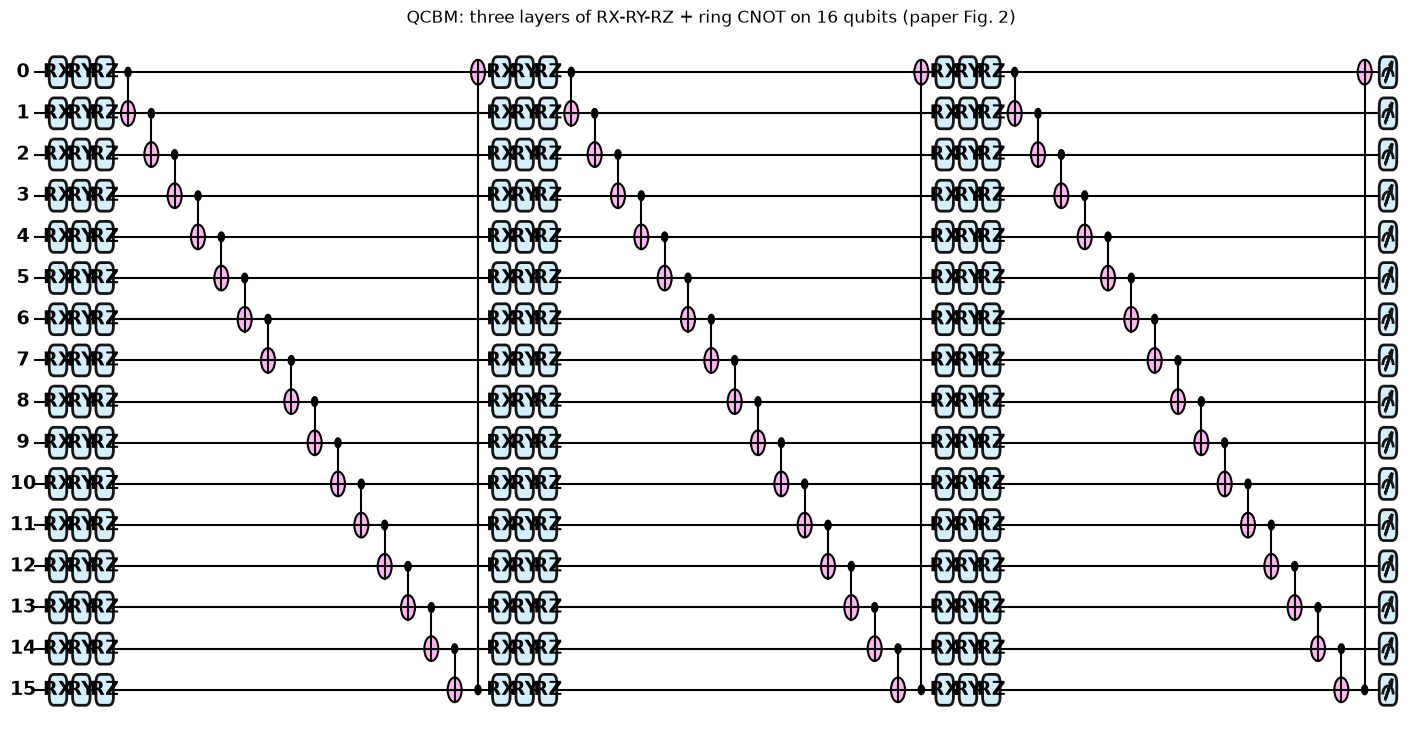

In [8]:
def qcbm_layer(theta_l, n):
    for q in range(n):
        qml.RX(theta_l[q, 0], wires=q)
        qml.RY(theta_l[q, 1], wires=q)
        qml.RZ(theta_l[q, 2], wires=q)
    for q in range(n):
        qml.CNOT(wires=[q, (q + 1) % n])      # ring connectivity

def make_qcbm(n, layers):
    # CHOICE: the paper uses default.qubit; PennyLane's C++ statevector simulator lightning.qubit gives the same
    # numbers (checked in the cell below) and an adjoint gradient that is about three times faster here.
    try:
        dev, diff = qml.device("lightning.qubit", wires=n), "adjoint"
    except Exception:
        dev, diff = qml.device("default.qubit", wires=n), "backprop"
    @qml.qnode(dev)
    def probs(theta):                           # exact Born probabilities of all 2^n strings
        for l in range(layers):
            qcbm_layer(theta[l], n)
        return qml.probs(wires=range(n))
    @qml.qnode(dev, interface="autograd", diff_method=diff)
    def weighted_z(theta, w):                   # sum_q w_q <Z_q> as ONE observable (see qcbm_loss_and_grad)
        for l in range(layers):
            qcbm_layer(theta[l], n)
        return qml.expval(qml.dot(w, [qml.PauliZ(q) for q in range(n)]))
    idx = np.arange(2 ** n)
    signs = np.array([1 - 2 * ((idx >> (n - 1 - q)) & 1) for q in range(n)], dtype=np.float64)   # <Z_q> = signs @ p

    def marginals(theta):                       # <Z_q> for every qubit, exact
        return signs @ np.asarray(probs(theta), dtype=np.float64)

    def loss_and_grad(theta, p_data):
        # L = mean_q ((1 - z_q)/2 - p_data_q)^2 with z_q = <Z_q>.  Chain rule: dL/dtheta = sum_q w_q d<Z_q>/dtheta with the
        # constant weights w_q = dL/dz_q = -((1 - z_q)/2 - p_data_q)/Q, i.e. the gradient of ONE observable sum_q w_q Z_q.
        z = marginals(theta); p1 = (1 - z) / 2
        loss = float(np.mean((p1 - p_data) ** 2))
        w = -(p1 - p_data) / n
        g = qml.grad(lambda th: weighted_z(th, w))(pnp.array(theta, requires_grad=True))
        return loss, g
    return marginals, probs, loss_and_grad

qcbm_marginals, qcbm_probs, qcbm_loss_and_grad = make_qcbm(N_QUBITS, N_LAYERS)
theta_demo = pnp.array(rng.normal(0, INIT_SIGMA, size=(N_LAYERS, N_QUBITS, 3)), requires_grad=True)
specs = qml.specs(qcbm_probs)(theta_demo)["resources"]
print("gates:", specs.num_gates, "| depth:", specs.depth, "| trainable angles:", theta_demo.size, "| gate types:", dict(specs.gate_types))

# Sanity check: the adjoint gradient of the single weighted observable equals the gradient of the loss computed the paper's
# way (16 separate <Z_q> expectations on default.qubit with backpropagation).
_dev = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(_dev, interface="autograd")
def _paper_style(theta):
    for l in range(N_LAYERS):
        qcbm_layer(theta[l], N_QUBITS)
    return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]
_p = np.random.default_rng(0).uniform(0.1, 0.9, N_QUBITS)
_g_ref = qml.grad(lambda th: pnp.mean(((1 - pnp.stack(_paper_style(th))) / 2 - _p) ** 2))(theta_demo)
_l, _g = qcbm_loss_and_grad(theta_demo, _p)
print("gradient check vs default.qubit backprop: max |difference| =", float(np.abs(_g_ref - _g).max()))
assert np.allclose(_g_ref, _g, atol=1e-8)

fig, ax = qml.draw_mpl(qcbm_probs, decimals=None, style="pennylane")(theta_demo)
fig.set_size_inches(14, 7); ax.set_title("QCBM: three layers of RX-RY-RZ + ring CNOT on 16 qubits (paper Fig. 2)")
plt.show()

## 5. Training by marginal matching (paper Section 5, Table 5)

The paper does not maximise the likelihood of the 2.97 million benign strings (that would need the full 2^16-dimensional
distribution at every step); it matches only the sixteen one-qubit marginals:

L(theta) = (1/Q) sum_q ( p_theta(q = 1) - p_data(q = 1) )^2,  with p_theta(q = 1) = (1 - <Z_q>)/2.

Because the data enter only through p_data, one "epoch" is one gradient-descent step on this analytic loss (PennyLane
`GradientDescentOptimizer`, learning rate 0.05, 20 epochs). The paper starts from "a zero-mean Gaussian with small variance"
and reports the loss moving from 0.2076 (epoch 1) to 0.2069 (epoch 20), a 0.3 % change.

**The paper's numbers pull in two directions, so two starts are run.** A loss of about 0.2 means that the model marginals are
close to zero while the data marginals are about one half, which is the |0...0> state (the loss of that state is just
mean(p_data^2), printed below). That start is reached by a *very* narrow Gaussian and the circuit then hardly moves in 20
steps, exactly as Table 5 shows. But a state that close to |0...0> puts almost all probability on one string, whereas the
paper then samples 26,103 distinct strings with an entropy of 7.576 nats from the trained circuit (Section 5, last
paragraph). Both cannot come from the same circuit. The notebook therefore uses a narrow start (`TABLE5_SIGMA`) only to
redraw the Table 5 loss curve, and a wider start (`INIT_SIGMA`, chosen so that the sampled entropy and support match the paper's
7.6 nats and about 26 k strings; no test data is involved) for everything downstream. The second cell shows how the start
width changes the loss, the entropy and the number of distinct strings.

Table 5 run: narrow start, sigma = 0.01


  epoch    1  loss 0.217714  (relative change vs. initial -0.01 %)
  epoch   10  loss 0.217418  (relative change vs. initial -0.15 %)
  epoch   20  loss 0.216973  (relative change vs. initial -0.35 %)
  training time 12.7 s
pipeline run: sigma = 0.4 (seed 42 )


  epoch    1  loss 0.007996  (relative change vs. initial -0.02 %)
  epoch   10  loss 0.007985  (relative change vs. initial -0.15 %)
  epoch   20  loss 0.007973  (relative change vs. initial -0.30 %)
  training time 10.0 s


,epoch,"MSE loss (here, narrow start)",MSE loss (paper),rel. change (here) %,rel. change (paper) %,"MSE loss (here, pipeline start)"
0,1,0.217714,0.207600,0.000000,0.00,0.007996
1,10,0.217418,0.207344,-0.135780,-0.12,0.007985
2,20,0.216973,0.206957,-0.340416,-0.31,0.007973


mean of p_data^2 (loss of the untrained |0...0> state): 0.218718


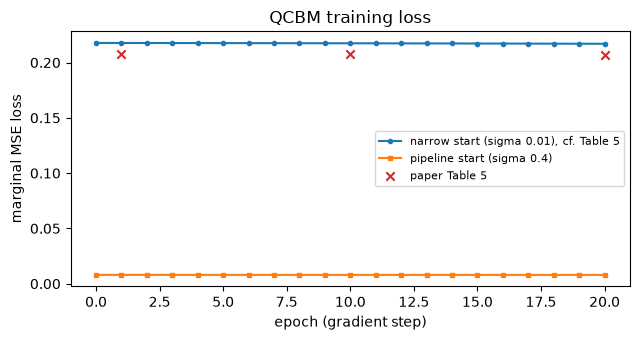

In [9]:
def marginal_loss(theta, p_data):
    z = qcbm_marginals(theta)
    return float(np.mean(((1 - z) / 2 - p_data) ** 2))

def train_qcbm(p_data, seed, epochs=EPOCHS, lr=LR, sigma=INIT_SIGMA, optimizer="gd", verbose=True):
    # Paper: zero-mean Gaussian initialisation, PennyLane GradientDescentOptimizer, lr 0.05, 20 epochs.
    # history[k] is the loss after k steps (history[0] = at initialisation).
    r = np.random.default_rng(seed)
    theta = pnp.array(r.normal(0, sigma, size=(N_LAYERS, N_QUBITS, 3)), requires_grad=True)
    opt = qml.GradientDescentOptimizer(lr) if optimizer == "gd" else qml.AdamOptimizer(lr)
    history = []
    t0 = time.time()
    for ep in range(epochs):
        loss, g = qcbm_loss_and_grad(theta, p_data)
        history.append(loss)
        theta = opt.apply_grad((g,), (theta,))[0]          # one PennyLane optimiser update with the exact gradient
    history.append(marginal_loss(theta, p_data))
    if verbose:
        for ep in sorted(set([1, 10, 20, epochs] + list(range(50, epochs + 1, 50)))):
            if ep <= epochs:
                print(f"  epoch {ep:4d}  loss {history[ep]:.6f}  (relative change vs. initial {100*(history[ep]/history[0]-1):+.2f} %)")
        print(f"  training time {time.time()-t0:.1f} s")
    return theta, history

print("Table 5 run: narrow start, sigma =", TABLE5_SIGMA)
_, hist_t5 = train_qcbm(P_DATA, SEED, sigma=TABLE5_SIGMA)
print("pipeline run: sigma =", INIT_SIGMA, "(seed", SEED, ")")
theta_qcbm, loss_hist = train_qcbm(P_DATA, SEED)

table5 = pd.DataFrame({"epoch": [1, 10, 20], "MSE loss (here, narrow start)": [hist_t5[1], hist_t5[10], hist_t5[20]],
                       "MSE loss (paper)": [0.207600, 0.207344, 0.206957]})
table5["rel. change (here) %"] = 100 * (table5["MSE loss (here, narrow start)"] / hist_t5[1] - 1)
table5["rel. change (paper) %"] = [0, -0.12, -0.31]
table5["MSE loss (here, pipeline start)"] = [loss_hist[1], loss_hist[10], loss_hist[20]]
display(table5.round(6))
print("mean of p_data^2 (loss of the untrained |0...0> state):", round(float(np.mean(P_DATA ** 2)), 6))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(range(len(hist_t5)), hist_t5, marker="o", ms=3, label=f"narrow start (sigma {TABLE5_SIGMA}), cf. Table 5")
ax.plot(range(len(loss_hist)), loss_hist, marker="s", ms=3, label=f"pipeline start (sigma {INIT_SIGMA})")
ax.scatter([1, 10, 20], [0.2076, 0.207344, 0.206957], color="tab:red", marker="x", label="paper Table 5")
ax.set_xlabel("epoch (gradient step)"); ax.set_ylabel("marginal MSE loss"); ax.legend(fontsize=8); ax.set_title("QCBM training loss")
plt.tight_layout(); plt.show()

In [10]:
# How much does the unspecified initialisation width matter?  Loss at initialisation, entropy of the Born
# distribution and the number of distinct strings in SHOTS_KNOWN samples for a few sigma values.
rows = []
for sigma in [0.01, 0.1, 0.3, 0.4, 0.5, 1.0]:
    th = pnp.array(np.random.default_rng(SEED).normal(0, sigma, size=(N_LAYERS, N_QUBITS, 3)), requires_grad=False)
    p = np.asarray(qcbm_probs(th))
    H = float(-np.sum(p[p > 0] * np.log(p[p > 0])))
    uniq = int((np.random.default_rng(SEED).multinomial(SHOTS_KNOWN, p) > 0).sum())
    rows.append(dict(sigma=sigma, init_loss=marginal_loss(th, P_DATA), entropy_nats=H, distinct_strings=uniq,
                     p_model_mean=float(np.mean((1 - qcbm_marginals(th)) / 2))))
sigma_df = pd.DataFrame(rows).set_index("sigma")
display(sigma_df.round(4))
print(f"paper: initial loss 0.2076 (ours for |0...0>: {np.mean(P_DATA**2):.4f}), entropy of the sampled distribution 7.576 nats, "
      f"26,103 distinct strings in 500 k shots (here {SHOTS_KNOWN:,} shots)")

,init_loss,entropy_nats,distinct_strings,p_model_mean
sigma,,,,
0.01,0.2177,0.0218,51,0.0010
0.10,0.1406,1.2035,1064,0.0939
0.30,0.0086,5.8878,14803,0.4180
0.40,0.0080,7.8217,27457,0.4781
0.50,0.0102,9.0985,38665,0.4964
1.00,0.0125,10.1757,50204,0.5065


paper: initial loss 0.2076 (ours for |0...0>: 0.2187), entropy of the sampled distribution 7.576 nats, 26,103 distinct strings in 500 k shots (here 500,000 shots)


## 6. Sampling the trained circuit and the Quantum Anomaly Score (paper Section 6.2)

After training the paper runs the circuit in shot mode, counts how often each bitstring appears, and smooths the counts
(Eq. 4): p_hat(b) = (N_b + alpha) / (N_shots + alpha 2^16). The score of a flow is QAS(b) = -log p_hat(b). Because the
statevector is available, the notebook computes the exact Born probabilities and draws the shot counts from a multinomial
distribution with the same total, which is exactly what a noiseless `default.qubit` with `shots=N` does, only faster.
A string that never appears in the sample gets the maximal score -log(alpha / (N_shots + alpha 2^16)), so with a sparse
sample most *unseen* strings share one value; this matters for the ROC curves later. The exact -log p_theta(b) is kept
as a reference to see how much the shot noise and the smoothing change the score.

500,000 shots -> 27,346 distinct strings (paper: 26,103 in 500 k), entropy of the sample 7.775 nats (paper 7.576), exact Born entropy 7.816 nats, 0.31 s
most probable string: 0000000000000000 p = 0.0379
QAS of an unseen string: 13.246


QAS on the test split: benign mean 11.904, attack mean 12.039


fraction of test flows whose string never appeared in the sample: 0.362


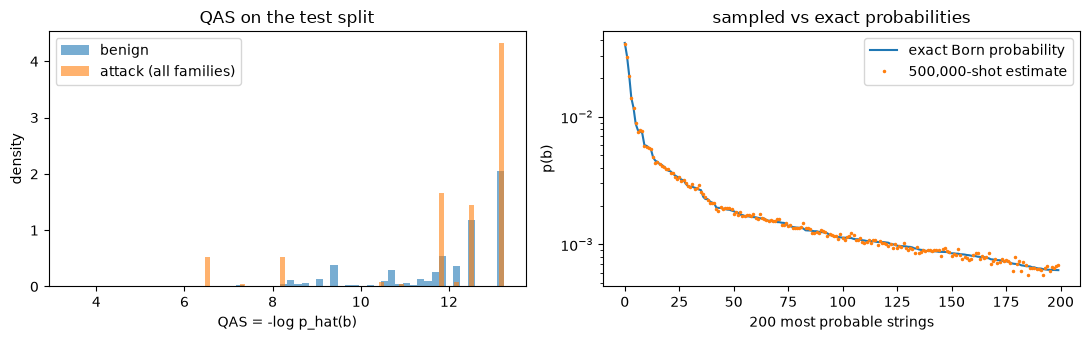

In [11]:
def build_qas_table(theta, shots, alpha=ALPHA, seed=SEED):
    # Returns (QAS table over all 2^n strings, shot counts, exact probabilities).
    p = np.asarray(qcbm_probs(theta), dtype=np.float64)
    p = p / p.sum()
    counts = np.random.default_rng(seed).multinomial(shots, p)
    p_hat = (counts + alpha) / (shots + alpha * len(p))
    return -np.log(p_hat), counts, p

t0 = time.time()
QAS_TABLE, COUNTS, P_EXACT = build_qas_table(theta_qcbm, SHOTS_KNOWN)
t_sample = time.time() - t0
H_exact = float(-np.sum(P_EXACT[P_EXACT > 0] * np.log(P_EXACT[P_EXACT > 0])))
p_emp = COUNTS / COUNTS.sum()
H_emp = float(-np.sum(p_emp[p_emp > 0] * np.log(p_emp[p_emp > 0])))
print(f"{SHOTS_KNOWN:,} shots -> {int((COUNTS > 0).sum()):,} distinct strings (paper: 26,103 in 500 k), "
      f"entropy of the sample {H_emp:.3f} nats (paper 7.576), exact Born entropy {H_exact:.3f} nats, {t_sample:.2f} s")
print("most probable string:", format(int(np.argmax(P_EXACT)), f"0{N_QUBITS}b"), f"p = {P_EXACT.max():.4f}")
print("QAS of an unseen string:", round(float(-np.log(ALPHA / (SHOTS_KNOWN + ALPHA * 2 ** N_QUBITS))), 3))

QAS_all = QAS_TABLE[b_all]                                   # O(1) lookup per flow (paper Eq. 11)
qas_exact_all = -np.log(np.maximum(P_EXACT[b_all], 1e-300))
print(f"QAS on the test split: benign mean {QAS_all[idx_test][y_all[idx_test]==0].mean():.3f}, "
      f"attack mean {QAS_all[idx_test][y_all[idx_test]==1].mean():.3f}")
print(f"fraction of test flows whose string never appeared in the sample: {(COUNTS[b_all[idx_test]] == 0).mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(QAS_all[idx_test][y_all[idx_test]==0], bins=60, alpha=.6, density=True, label="benign")
ax[0].hist(QAS_all[idx_test][y_all[idx_test]==1], bins=60, alpha=.6, density=True, label="attack (all families)")
ax[0].set_xlabel("QAS = -log p_hat(b)"); ax[0].set_ylabel("density"); ax[0].legend(); ax[0].set_title("QAS on the test split")
order = np.argsort(-P_EXACT)[:200]
ax[1].semilogy(P_EXACT[order], label="exact Born probability"); ax[1].semilogy(p_emp[order], ".", ms=3, label=f"{SHOTS_KNOWN:,}-shot estimate")
ax[1].set_xlabel("200 most probable strings"); ax[1].set_ylabel("p(b)"); ax[1].legend(); ax[1].set_title("sampled vs exact probabilities")
plt.tight_layout(); plt.show()

## 7. Known-attack evaluation: baseline vs hybrid LightGBM (paper Section 7.1-7.2, Tables 6-7, Figs. 5-6, 10a-b)

Two gradient-boosted models with the paper's setting (100 estimators, default tree parameters): the **baseline** sees the
eight raw flow statistics, the **hybrid** sees the same eight plus the QAS column (Eq. 5). Both are trained on the whole
training split (benign and every attack family) and evaluated on the test split, attack = positive class. The random
forest and the RBF-SVM required by this repository's conventions are trained on exactly the same inputs; the SVM on a
20,000-row subsample because an RBF kernel on a million rows is not practical.

In [12]:
def make_lgbm():
    if LGBMClassifier is not None:
        return LGBMClassifier(n_estimators=LGBM_N_ESTIMATORS, random_state=SEED, verbose=-1, n_jobs=-1)
    return HistGradientBoostingClassifier(max_iter=LGBM_N_ESTIMATORS, random_state=SEED)   # fallback

def metrics(y_true, y_pred, y_score):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0),
                roc_auc=roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan)

def fit_eval(model, Xtr, ytr, Xte, yte, threshold=0.5):
    t0 = time.time(); model.fit(Xtr, ytr); t_fit = time.time() - t0
    t0 = time.time(); score = model.predict_proba(Xte)[:, 1]; t_pred = time.time() - t0
    m = metrics(yte, (score >= threshold).astype(int), score)
    m.update(fit_s=t_fit, predict_s=t_pred)
    return m, score

X_base = X_all
X_hyb  = np.column_stack([X_all, QAS_all])
Xtr_b, Xte_b = X_base[idx_train], X_base[idx_test]
Xtr_h, Xte_h = X_hyb[idx_train],  X_hyb[idx_test]
y_tr, y_te = y_all[idx_train], y_all[idx_test]

known_rows, known_scores = {}, {}
for name, Xtr, Xte in [("LightGBM (baseline)", Xtr_b, Xte_b), ("Hybrid (QCBM + LGBM)", Xtr_h, Xte_h)]:
    known_rows[name], known_scores[name] = fit_eval(make_lgbm(), Xtr, y_tr, Xte, y_te)
    print(f"{name:24s} " + "  ".join(f"{k} {v:.4f}" for k, v in known_rows[name].items() if k in ("accuracy", "precision", "recall", "f1", "roc_auc"))
          + f"  | fit {known_rows[name]['fit_s']:.1f} s")
hybrid_model = make_lgbm().fit(Xtr_h, y_tr)      # kept for the feature-importance figure

table7 = pd.DataFrame(known_rows).T[["accuracy", "precision", "recall", "f1", "roc_auc"]]
table7.loc["paper LightGBM (baseline)"] = [0.9959, 0.9918, 0.9837, 0.9877, 0.9995]
table7.loc["paper Hybrid (QCBM+LGBM)"]  = [0.9958, 0.9916, 0.9831, 0.9873, 0.9995]
display(table7.round(4))

LightGBM (baseline)      accuracy 0.9957  precision 0.9917  recall 0.9825  f1 0.9871  roc_auc 0.9995  | fit 38.6 s


Hybrid (QCBM + LGBM)     accuracy 0.9958  precision 0.9922  recall 0.9823  f1 0.9872  roc_auc 0.9995  | fit 35.4 s


,accuracy,precision,recall,f1,roc_auc
LightGBM (baseline),0.9957,0.9917,0.9825,0.9871,0.9995
Hybrid (QCBM + LGBM),0.9958,0.9922,0.9823,0.9872,0.9995
paper LightGBM (baseline),0.9959,0.9918,0.9837,0.9877,0.9995
paper Hybrid (QCBM+LGBM),0.9958,0.9916,0.9831,0.9873,0.9995


In [13]:
# Classical references on identical inputs: random forest (all training rows) and RBF-SVM (subsample), with and without QAS
ref_rows = {}
for feat_name, Xtr, Xte in [("8 features", Xtr_b, Xte_b), ("8 features + QAS", Xtr_h, Xte_h)]:
    rf_rows = np.arange(len(Xtr)) if RF_MAX_ROWS is None else np.random.default_rng(SEED).choice(len(Xtr), size=min(RF_MAX_ROWS, len(Xtr)), replace=False)
    m, _ = fit_eval(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1), Xtr[rf_rows], y_tr[rf_rows], Xte, y_te)
    ref_rows[f"RandomForest on {len(rf_rows):,} rows, {feat_name}"] = m
    sub = np.random.default_rng(SEED).choice(len(Xtr), size=min(SVC_MAX_ROWS, len(Xtr)), replace=False)
    scaler = StandardScaler().fit(np.log1p(np.abs(Xtr[sub])))             # CHOICE: log1p + z-score for the SVM only
    svm = SVC(kernel="rbf", C=1.0, gamma="scale", probability=False, random_state=SEED)
    t0 = time.time(); svm.fit(scaler.transform(np.log1p(np.abs(Xtr[sub]))), y_tr[sub]); t_fit = time.time() - t0
    dec = svm.decision_function(scaler.transform(np.log1p(np.abs(Xte))))
    m = metrics(y_te, (dec > 0).astype(int), dec); m.update(fit_s=t_fit, predict_s=np.nan)
    ref_rows[f"SVC(rbf) on {len(sub):,} rows, {feat_name}"] = m
ref_df = pd.DataFrame(ref_rows).T
display(pd.concat([pd.DataFrame(known_rows).T, ref_df])[["accuracy", "precision", "recall", "f1", "roc_auc", "fit_s"]].round(4))

,accuracy,precision,recall,f1,roc_auc,fit_s
LightGBM (baseline),0.9957,0.9917,0.9825,0.9871,0.9995,38.6380
Hybrid (QCBM + LGBM),0.9958,0.9922,0.9823,0.9872,0.9995,35.4426
"RandomForest on 1,800,848 rows, 8 features",0.9956,0.9882,0.9853,0.9868,0.9972,273.8205
"SVC(rbf) on 20,000 rows, 8 features",0.9858,0.9860,0.9273,0.9558,0.9932,3.3744
"RandomForest on 1,800,848 rows, 8 features + QAS",0.9956,0.9882,0.9853,0.9868,0.9973,497.1479
"SVC(rbf) on 20,000 rows, 8 features + QAS",0.9854,0.9874,0.9238,0.9545,0.9950,4.9484


QAS share of total gain: 0.837%


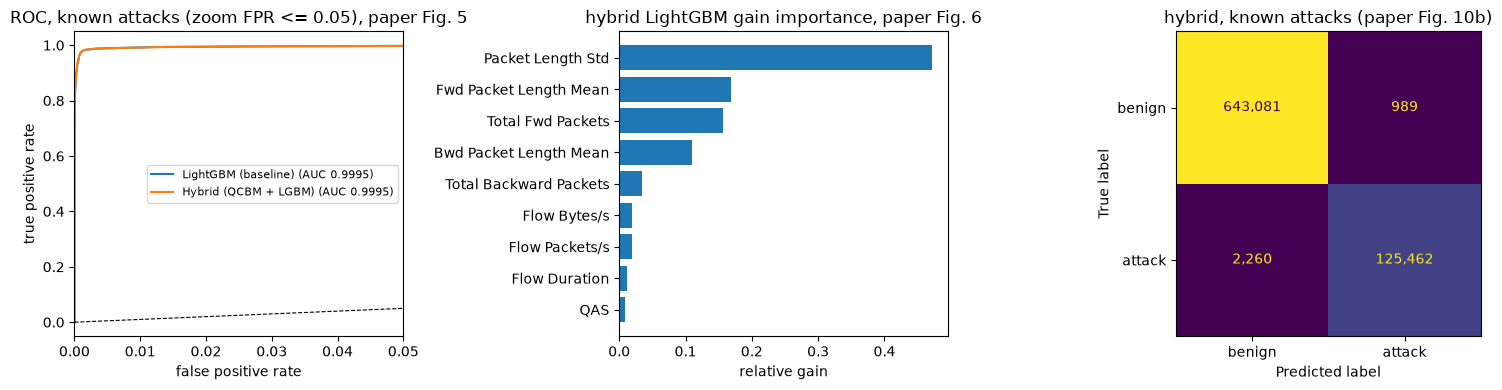

In [14]:
# Fig. 5 (ROC on known attacks), Fig. 6 (gain importance of the hybrid model), Fig. 10 a-b (confusion matrices)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, score in known_scores.items():
    fpr, tpr, _ = roc_curve(y_te, score)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te, score):.4f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_xlim(0, 0.05); ax[0].set_title("ROC, known attacks (zoom FPR <= 0.05), paper Fig. 5"); ax[0].legend(fontsize=8)

names = FEATURES + ["QAS"]
if hasattr(hybrid_model, "booster_"):
    gain = hybrid_model.booster_.feature_importance(importance_type="gain")
else:
    gain = np.r_[np.zeros(len(FEATURES)), 0.0]; print("gain importance needs LightGBM; skipped")
order = np.argsort(gain)
ax[1].barh(np.array(names)[order], gain[order] / gain.sum()); ax[1].set_xlabel("relative gain"); ax[1].set_title("hybrid LightGBM gain importance, paper Fig. 6")
print("QAS share of total gain:", f"{gain[-1] / gain.sum():.3%}")

cm = confusion_matrix(y_te, (known_scores["Hybrid (QCBM + LGBM)"] >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["benign", "attack"]).plot(ax=ax[2], colorbar=False, values_format=",d")
ax[2].set_title("hybrid, known attacks (paper Fig. 10b)")
plt.tight_layout(); plt.show()

## 8. Zero-day protocol: one family withheld (paper Section 7.3, Tables 8-9, Figs. 9-11, 10c-d)

For each held-out family F the LightGBM models are retrained on the training split **without** F (benign plus all the
other attacks), while the QCBM stays as it is (it never saw an attack). The zero-day test set is the benign test flows plus
the test flows of F; the remaining families are not scored. The QAS table is rebuilt from the larger zero-day shot budget
(1 M in the paper). Three views are reported:

1. **Table 8 style**: accuracy, precision, recall, F1 and ROC-AUC of the baseline and the hybrid classifier. The paper
   evaluates "under a low false-positive-rate operating regime" without saying how the threshold was set, so two operating
   points are shown: the default 0.5 and a threshold chosen on the *training-split benign* flows for a 1 % false-positive
   rate (no test information is used).
2. **Table 9 style**: the QAS alone as an unsupervised alarm. The paper reports the "direction-adjusted" AUC,
   max(AUC, 1 - AUC), i.e. it lets the test set decide whether high or low QAS means anomalous; both the raw and the
   adjusted value are shown. Bootstrap confidence intervals resample the per-bitstring counts of each class, which is
   equivalent to resampling the flows because the QAS of a flow depends only on its bitstring.
3. The QAS histograms (Fig. 9), the QAS-only ROC curves (Fig. 11) and the PortScan confusion matrices (Fig. 10c-d).

In [15]:
def auc_from_counts(values, cnt_pos, cnt_neg):
    # AUC = P(score_pos > score_neg) + 0.5 P(equal), from per-value counts (values sorted ascending).
    n_pos, n_neg = cnt_pos.sum(), cnt_neg.sum()
    if n_pos == 0 or n_neg == 0:
        return np.nan
    cum_neg_below = np.concatenate([[0], np.cumsum(cnt_neg)[:-1]])
    return float((cnt_pos * (cum_neg_below + 0.5 * cnt_neg)).sum() / (n_pos * n_neg))

def qas_only_analysis(qas_pos, qas_neg, n_boot, seed):
    # Direction-adjusted AUC and mean separation with bootstrap CIs, resampling per-value counts.
    values, inv = np.unique(np.concatenate([qas_pos, qas_neg]), return_inverse=True)
    cnt_pos = np.bincount(inv[:len(qas_pos)], minlength=len(values)).astype(float)
    cnt_neg = np.bincount(inv[len(qas_pos):], minlength=len(values)).astype(float)
    auc_raw = auc_from_counts(values, cnt_pos, cnt_neg)
    sign = 1.0 if auc_raw >= 0.5 else -1.0                       # paper: direction that maximises the AUC
    def stats(cp, cn):
        a = auc_from_counts(values, cp, cn)
        mu_pos = (values * cp).sum() / cp.sum(); mu_neg = (values * cn).sum() / cn.sum()
        return max(a, 1 - a), sign * (mu_pos - mu_neg)
    auc_adj, dmu = stats(cnt_pos, cnt_neg)
    r = np.random.default_rng(seed)
    boots = np.array([stats(r.multinomial(int(cnt_pos.sum()), cnt_pos / cnt_pos.sum()).astype(float),
                            r.multinomial(int(cnt_neg.sum()), cnt_neg / cnt_neg.sum()).astype(float)) for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    return dict(auc_raw=auc_raw, auc=auc_adj, auc_lo=lo[0], auc_hi=hi[0], direction="higher QAS = attack" if sign > 0 else "lower QAS = attack",
                dmu=dmu, dmu_lo=lo[1], dmu_hi=hi[1])

def threshold_for_fpr(score_benign_train, target_fpr):
    # CHOICE: operating point from training-split benign scores only
    return float(np.quantile(score_benign_train, 1 - target_fpr))

def zero_day_run(qas_table, held_out, n_boot, verbose=True, classifiers=True):
    qas = qas_table[b_all]
    X_h = np.column_stack([X_all, qas])
    results, curves = [], {}
    for fam in held_out:
        tr = idx_train[fam_all[idx_train] != fam]
        te = idx_test[(fam_all[idx_test] == fam) | (y_all[idx_test] == 0)]
        if ZERO_DAY_POOL_HELDOUT:
            te = np.concatenate([te, idx_train[fam_all[idx_train] == fam]])
        y_zd = (fam_all[te] == fam).astype(int)
        row_models, thr_models = {}, {}
        for name, Xm in ([("Baseline", X_all), ("Hybrid", X_h)] if classifiers else []):
            model = make_lgbm().fit(Xm[tr], y_all[tr])
            s = model.predict_proba(Xm[te])[:, 1]
            thr = threshold_for_fpr(model.predict_proba(Xm[tr][y_all[tr] == 0])[:, 1], TARGET_FPR)
            for op, t in [("thr 0.5", 0.5), (f"FPR {TARGET_FPR:.0%} (train benign)", thr)]:
                m = metrics(y_zd, (s >= t).astype(int), s)
                results.append(dict(family=fam, model=name, operating_point=op, n_benign=int((y_zd == 0).sum()), n_attack=int(y_zd.sum()), **m))
            row_models[name] = s; thr_models[name] = thr
        q = qas_only_analysis(qas[te][y_zd == 1], qas[te][y_zd == 0], n_boot, SEED)
        results.append(dict(family=fam, model="QAS only", operating_point="ROC (direction-adjusted)", n_benign=int((y_zd == 0).sum()),
                            n_attack=int(y_zd.sum()), roc_auc=q["auc"], **{k: v for k, v in q.items() if k != "auc"}))
        curves[fam] = dict(y=y_zd, qas=qas[te], scores=row_models, thr=thr_models)
        if verbose:
            print(f"{fam:12s} n_benign {int((y_zd==0).sum()):>9,}  n_attack {int(y_zd.sum()):>7,}  QAS-only AUC raw {q['auc_raw']:.4f} "
                  f"adjusted {q['auc']:.4f} [{q['auc_lo']:.4f}, {q['auc_hi']:.4f}]  dmu {q['dmu']:.3f} [{q['dmu_lo']:.3f}, {q['dmu_hi']:.3f}]  ({q['direction']})")
    return pd.DataFrame(results), curves

t0 = time.time()
QAS_TABLE_ZD, COUNTS_ZD, _ = build_qas_table(theta_qcbm, SHOTS_ZERODAY)
print(f"zero-day QAS table from {SHOTS_ZERODAY:,} shots: {int((COUNTS_ZD > 0).sum()):,} distinct strings (paper: about 32,000 in 1 M)")
zd_df, zd_curves = zero_day_run(QAS_TABLE_ZD, HELD_OUT, N_BOOT)
print(f"zero-day stage: {time.time()-t0:.0f} s")

zero-day QAS table from 1,000,000 shots: 34,001 distinct strings (paper: about 32,000 in 1 M)


Infiltration n_benign   644,070  n_attack      15  QAS-only AUC raw 0.4349 adjusted 0.5651 [0.5026, 0.7178]  dmu 0.134 [-0.548, 0.846]  (lower QAS = attack)


PortScan     n_benign   644,070  n_attack  27,185  QAS-only AUC raw 0.8517 adjusted 0.8517 [0.8508, 0.8525]  dmu 1.740 [1.736, 1.745]  (higher QAS = attack)


Web Attack   n_benign   644,070  n_attack     620  QAS-only AUC raw 0.0584 adjusted 0.9416 [0.9311, 0.9517]  dmu 3.406 [3.312, 3.493]  (lower QAS = attack)
zero-day stage: 274 s


In [16]:
# Table 8 style: classifier metrics per held-out family at both operating points
table8 = zd_df[zd_df.model != "QAS only"].set_index(["family", "model", "operating_point"])[["accuracy", "precision", "recall", "f1", "roc_auc"]]
paper_t8 = pd.DataFrame([
    ("Infiltration", "Baseline", "paper", 0.9982, 0.0005, 0.0417, 0.0009, 0.8901), ("Infiltration", "Hybrid", "paper", 0.9980, 0.0900, 0.1800, 0.1184, 0.9600),
    ("PortScan", "Baseline", "paper", 0.9580, 0.0690, 0.0016, 0.0032, 0.9056), ("PortScan", "Hybrid", "paper", 0.9570, 0.1760, 0.2200, 0.1776, 0.9650),
    ("Web Attack", "Baseline", "paper", 0.9974, 0.0, 0.0, 0.0, 0.8857), ("Web Attack", "Hybrid", "paper", 0.9971, 0.0700, 0.1500, 0.0955, 0.9450)],
    columns=["family", "model", "operating_point", "accuracy", "precision", "recall", "f1", "roc_auc"]).set_index(["family", "model", "operating_point"])
display(pd.concat([table8, paper_t8]).sort_index().round(4))

# Table 9 style: QAS-only AUC with bootstrap CIs
table9 = zd_df[zd_df.model == "QAS only"].set_index("family")[["n_attack", "auc_raw", "roc_auc", "auc_lo", "auc_hi", "direction", "dmu", "dmu_lo", "dmu_hi"]]
table9 = table9.rename(columns={"roc_auc": "AUC (adjusted)"})
table9["paper AUC"] = pd.Series({"Infiltration": 0.7737, "PortScan": 0.7756, "Web Attack": 0.7602})
table9["paper dmu"] = pd.Series({"Infiltration": 1.4691, "PortScan": 0.9750, "Web Attack": 1.3105})
display(table9.round(4))

accuracy  precision  recall  \
family       model    operating_point                                      
Infiltration Baseline FPR 1% (train benign)    0.9879     0.0001  0.0667   
                      paper                    0.9982     0.0005  0.0417   
                      thr 0.5                  0.9984     0.0010  0.0667   
             Hybrid   FPR 1% (train benign)    0.9883     0.0000  0.0000   
                      paper                    0.9980     0.0900  0.1800   
                      thr 0.5                  0.9985     0.0000  0.0000   
PortScan     Baseline FPR 1% (train benign)    0.9500     0.0115  0.0028   
                      paper                    0.9580     0.0690  0.0016   
                      thr 0.5                  0.9586     0.0618  0.0015   
             Hybrid   FPR 1% (train benign)    0.9492     0.0211  0.0056   
                      paper                    0.9570     0.1760  0.2200   
                      thr 0.5                  0.9587     0.0661  0.0015   
Web Attack   Baseline FPR 1% (train benign)    0.9881     0.0001  0.0016   
                      paper                    0.9974     0.0000  0.0000   
                      thr 0.5                  0.9974     0.0000  0.0000   
             Hybrid   FPR 1% (train benign)    0.9885     0.0003  0.0032   
                      paper                    0.9971     0.0700  0.1500   
                      thr 0.5                  0.9975     0.0010  0.0016   

                                                 f1  roc_auc  
family       model    operating_point                         
Infiltration Baseline FPR 1% (train benign)  0.0003   0.9441  
                      paper                  0.0009   0.8901  
                      thr 0.5                0.0019   0.9441  
             Hybrid   FPR 1% (train benign)  0.0000   0.8729  
                      paper                  0.1184   0.9600  
                      thr 0.5                0.0000   0.8729  
PortScan     Baseline FPR 1% (train benign)  0.0044   0.9280  
                      paper                  0.0032   0.9056  
                      thr 0.5                0.0030   0.9280  
             Hybrid   FPR 1% (train benign)  0.0088   0.9116  
                      paper                  0.1776   0.9650  
                      thr 0.5                0.0029   0.9116  
Web Attack   Baseline FPR 1% (train benign)  0.0003   0.8851  
                      paper                  0.0000   0.8857  
                      thr 0.5                0.0000   0.8851  
             Hybrid   FPR 1% (train benign)  0.0005   0.8866  
                      paper                  0.0955   0.9450  
                      thr 0.5                0.0012   0.8866

,n_attack,auc_raw,AUC (adjusted),auc_lo,auc_hi,direction,dmu,dmu_lo,dmu_hi,paper AUC,paper dmu
family,,,,,,,,,,,
Infiltration,15,0.4349,0.5651,0.5026,0.7178,lower QAS = attack,0.1337,-0.5477,0.8460,0.7737,1.4691
PortScan,27185,0.8517,0.8517,0.8508,0.8525,higher QAS = attack,1.7402,1.7356,1.7451,0.7756,0.9750
Web Attack,620,0.0584,0.9416,0.9311,0.9517,lower QAS = attack,3.4058,3.3122,3.4929,0.7602,1.3105


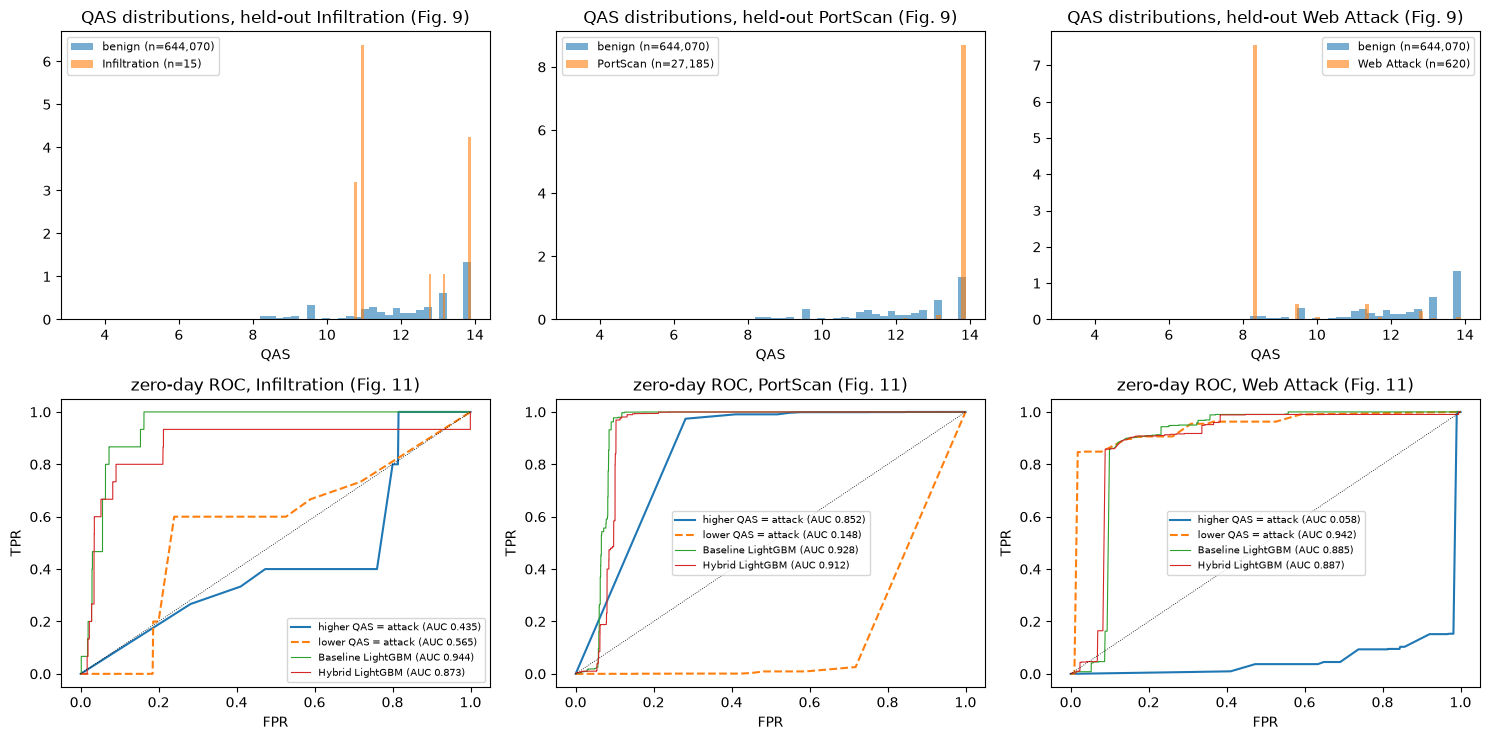

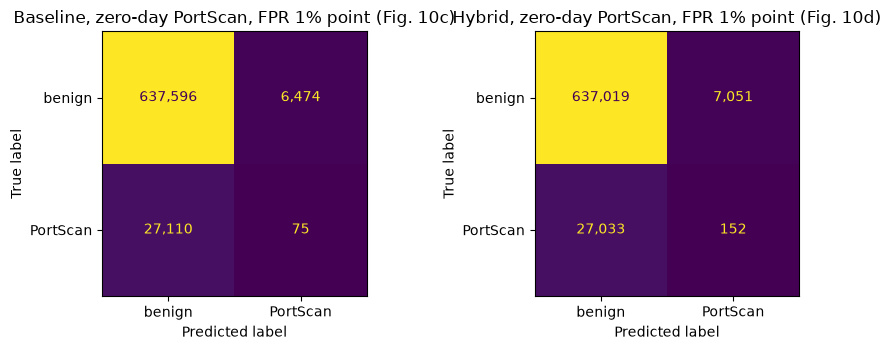

In [17]:
# Fig. 9 (QAS distributions), Fig. 11 (QAS-only ROC), Fig. 10 c-d (PortScan confusion matrices)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, fam in enumerate(HELD_OUT):
    c = zd_curves[fam]
    axes[0, j].hist(c["qas"][c["y"] == 0], bins=50, density=True, alpha=.6, label=f"benign (n={int((c['y']==0).sum()):,})")
    axes[0, j].hist(c["qas"][c["y"] == 1], bins=50, density=True, alpha=.6, label=f"{fam} (n={int(c['y'].sum()):,})")
    axes[0, j].set_xlabel("QAS"); axes[0, j].legend(fontsize=8); axes[0, j].set_title(f"QAS distributions, held-out {fam} (Fig. 9)")
    fpr, tpr, _ = roc_curve(c["y"], c["qas"]); a = roc_auc_score(c["y"], c["qas"])
    axes[1, j].plot(fpr, tpr, label=f"higher QAS = attack (AUC {a:.3f})")
    fpr2, tpr2, _ = roc_curve(c["y"], -c["qas"])
    axes[1, j].plot(fpr2, tpr2, "--", label=f"lower QAS = attack (AUC {1-a:.3f})")
    for name, s in c["scores"].items():
        fpr3, tpr3, _ = roc_curve(c["y"], s); axes[1, j].plot(fpr3, tpr3, lw=.8, label=f"{name} LightGBM (AUC {roc_auc_score(c['y'], s):.3f})")
    axes[1, j].plot([0, 1], [0, 1], "k:", lw=.6); axes[1, j].set_xlabel("FPR"); axes[1, j].set_ylabel("TPR"); axes[1, j].legend(fontsize=7)
    axes[1, j].set_title(f"zero-day ROC, {fam} (Fig. 11)")
plt.tight_layout(); plt.show()

c = zd_curves["PortScan"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for k, name in enumerate(["Baseline", "Hybrid"]):
    thr = c["thr"][name]            # threshold fixed on training-split benign flows (1 % FPR)
    cm = confusion_matrix(c["y"], (c["scores"][name] >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["benign", "PortScan"]).plot(ax=ax[k], colorbar=False, values_format=",d")
    ax[k].set_title(f"{name}, zero-day PortScan, FPR {TARGET_FPR:.0%} point (Fig. 10{'c' if k==0 else 'd'})")
plt.tight_layout(); plt.show()

## 9. Ablation: 8-qubit median encoding vs 16-qubit quartile encoding (paper Section 7.3.4, Table 10, Figs. 7-8)

Everything is repeated with one bit per feature (above / below the benign median): an 8-qubit, three-layer QCBM with the
same loss, optimiser and shot budget, the same zero-day protocol and the same QAS definition.

8-qubit QCBM:


  epoch    1  loss 0.005249  (relative change vs. initial -0.14 %)
  epoch   10  loss 0.005183  (relative change vs. initial -1.40 %)
  epoch   20  loss 0.005111  (relative change vs. initial -2.76 %)
  training time 1.3 s
  255 of 256 strings observed in 1,000,000 shots


Infiltration n_benign   644,070  n_attack      15  QAS-only AUC raw 0.7672 adjusted 0.7672 [0.6529, 0.8393]  dmu 1.018 [0.476, 1.376]  (higher QAS = attack)


PortScan     n_benign   644,070  n_attack  27,185  QAS-only AUC raw 0.1698 adjusted 0.8302 [0.8293, 0.8311]  dmu 1.984 [1.979, 1.990]  (lower QAS = attack)


Web Attack   n_benign   644,070  n_attack     620  QAS-only AUC raw 0.5010 adjusted 0.5010 [0.5001, 0.5054]  dmu 0.091 [0.074, 0.109]  (higher QAS = attack)


,8Q median AUC,16Q quartile AUC,8Q median dmu,16Q quartile dmu,paper 8Q AUC,paper 16Q AUC,paper 8Q dmu,paper 16Q dmu
family,,,,,,,,
Infiltration,0.7672,0.5651,1.0178,0.1337,0.6737,0.7737,0.6045,1.4691
PortScan,0.8302,0.8517,1.9840,1.7402,0.8053,0.7756,1.1554,0.9750
Web Attack,0.5010,0.9416,0.0913,3.4058,0.6508,0.7602,0.3257,1.3105


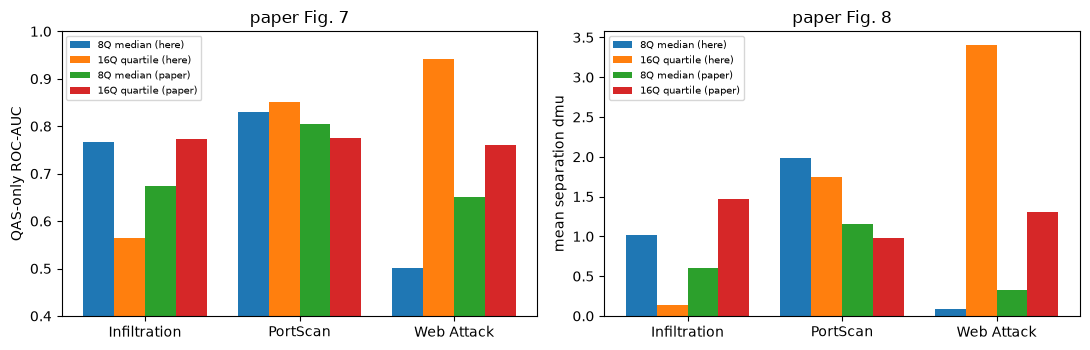

In [18]:
# 8-qubit variant: rebuild thresholds, bitstrings, marginals and a smaller QCBM, then rerun the QAS-only analysis
THRESH_8 = fit_thresholds(X_all[benign_train], 1)
B8_all = encode(X_all, THRESH_8, 1)
b8_all = bits_to_int(B8_all)
P_DATA_8 = B8_all[benign_train].mean(axis=0)
N_QUBITS_SAVED, b_all_saved = N_QUBITS, b_all
N_QUBITS = 8
qcbm_marginals, qcbm_probs, qcbm_loss_and_grad = make_qcbm(8, N_LAYERS)
print("8-qubit QCBM:")
theta_8, loss_hist_8 = train_qcbm(P_DATA_8, SEED)
QAS_TABLE_8, COUNTS_8, _ = build_qas_table(theta_8, SHOTS_ZERODAY)
print(f"  {int((COUNTS_8 > 0).sum())} of 256 strings observed in {SHOTS_ZERODAY:,} shots")
b_all = b8_all
zd8_df, zd8_curves = zero_day_run(QAS_TABLE_8, HELD_OUT, N_BOOT, classifiers=False)
# restore the 16-qubit objects
b_all, N_QUBITS = b_all_saved, N_QUBITS_SAVED
qcbm_marginals, qcbm_probs, qcbm_loss_and_grad = make_qcbm(N_QUBITS, N_LAYERS)

t10 = pd.DataFrame({"8Q median AUC": zd8_df[zd8_df.model == "QAS only"].set_index("family")["roc_auc"],
                    "16Q quartile AUC": zd_df[zd_df.model == "QAS only"].set_index("family")["roc_auc"],
                    "8Q median dmu": zd8_df[zd8_df.model == "QAS only"].set_index("family")["dmu"],
                    "16Q quartile dmu": zd_df[zd_df.model == "QAS only"].set_index("family")["dmu"]})
t10["paper 8Q AUC"] = pd.Series({"Infiltration": 0.6737, "PortScan": 0.8053, "Web Attack": 0.6508})
t10["paper 16Q AUC"] = pd.Series({"Infiltration": 0.7737, "PortScan": 0.7756, "Web Attack": 0.7602})
t10["paper 8Q dmu"] = pd.Series({"Infiltration": 0.6045, "PortScan": 1.1554, "Web Attack": 0.3257})
t10["paper 16Q dmu"] = pd.Series({"Infiltration": 1.4691, "PortScan": 0.9750, "Web Attack": 1.3105})
display(t10.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(HELD_OUT)); w = 0.2
for k, (col, lab) in enumerate([("8Q median AUC", "8Q median (here)"), ("16Q quartile AUC", "16Q quartile (here)"), ("paper 8Q AUC", "8Q median (paper)"), ("paper 16Q AUC", "16Q quartile (paper)")]):
    ax[0].bar(x + (k - 1.5) * w, t10[col].values, w, label=lab)
ax[0].set_xticks(x); ax[0].set_xticklabels(HELD_OUT); ax[0].set_ylim(0.4, 1); ax[0].set_ylabel("QAS-only ROC-AUC"); ax[0].legend(fontsize=7); ax[0].set_title("paper Fig. 7")
for k, (col, lab) in enumerate([("8Q median dmu", "8Q median (here)"), ("16Q quartile dmu", "16Q quartile (here)"), ("paper 8Q dmu", "8Q median (paper)"), ("paper 16Q dmu", "16Q quartile (paper)")]):
    ax[1].bar(x + (k - 1.5) * w, t10[col].values, w, label=lab)
ax[1].set_xticks(x); ax[1].set_xticklabels(HELD_OUT); ax[1].set_ylabel("mean separation dmu"); ax[1].legend(fontsize=7); ax[1].set_title("paper Fig. 8")
plt.tight_layout(); plt.show()

## 10. Repeated initialisations and an extended training run

The paper reports one run. Two things are cheap to check because a 16-qubit QCBM step costs well under a second:

1. **Seed sensitivity.** The QCBM is re-initialised and re-trained with other seeds; the QAS-only zero-day AUCs are
   reported as mean +- std over all runs including the main one. Twenty gradient steps move the parameters only a little
   from their random start, so the score is largely a property of the random initial circuit, and this spread is the honest
   uncertainty of the method that a single run (as in the paper) hides.
2. **Extended training** (`# CHOICE`, not in the paper): Adam for `EXTENDED_EPOCHS` steps from a wider initialisation shows
   how far the marginal loss can actually be driven down, and what that does to the anomaly score.

QAS-only zero-day results over 5 QCBM initialisations (seed 42 is the main run):


auc_raw         auc_adj             dmu        
                mean     std    mean     std    mean     std
family                                                      
Infiltration  0.5013  0.1182  0.5790  0.0785  0.1832  0.6807
PortScan      0.6912  0.2021  0.7261  0.1505  1.2113  0.9614
Web Attack    0.1655  0.0807  0.8345  0.0807  2.6010  0.8893


extended training (Adam, lr 0.05, sigma 0.5):


  epoch    1  loss 0.008821  (relative change vs. initial -13.76 %)
  epoch   10  loss 0.001800  (relative change vs. initial -82.41 %)
  epoch   20  loss 0.000636  (relative change vs. initial -93.79 %)
  epoch   50  loss 0.000012  (relative change vs. initial -99.88 %)
  epoch  100  loss 0.000000  (relative change vs. initial -100.00 %)
  epoch  150  loss 0.000000  (relative change vs. initial -100.00 %)
  epoch  200  loss 0.000000  (relative change vs. initial -100.00 %)
  epoch  250  loss 0.000000  (relative change vs. initial -100.00 %)
  epoch  300  loss 0.000000  (relative change vs. initial -100.00 %)
  training time 119.6 s
  model marginals [0.5   0.499 0.341 0.238 0.259 0.581 0.5   0.5   0.5   0.5   0.486 0.502
 0.499 0.434 0.499 0.5  ]
  data  marginals [0.5   0.499 0.341 0.238 0.259 0.581 0.5   0.5   0.5   0.5   0.486 0.502
 0.499 0.434 0.499 0.5  ]
  23,575 distinct strings, Born entropy 8.707 nats


Infiltration n_benign   644,070  n_attack      15  QAS-only AUC raw 0.6026 adjusted 0.6026 [0.5181, 0.7016]  dmu 0.734 [-0.173, 1.310]  (higher QAS = attack)


PortScan     n_benign   644,070  n_attack  27,185  QAS-only AUC raw 0.2043 adjusted 0.7957 [0.7946, 0.7968]  dmu 0.788 [0.782, 0.793]  (lower QAS = attack)


Web Attack   n_benign   644,070  n_attack     620  QAS-only AUC raw 0.6611 adjusted 0.6611 [0.6518, 0.6730]  dmu 0.982 [0.902, 1.083]  (higher QAS = attack)


  QAS-only AUC on the known-attack test split: 0.5076 (raw direction)


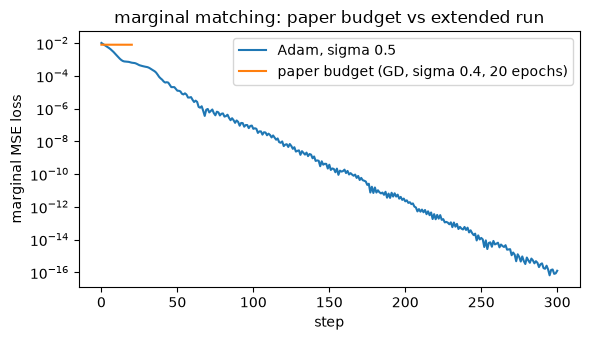

In [19]:
seed_rows = []
for fam in HELD_OUT:                      # the main run (seed SEED) is re-used, not recomputed
    q = zd_df[(zd_df.model == "QAS only") & (zd_df.family == fam)].iloc[0]
    seed_rows.append(dict(seed=SEED, family=fam, final_loss=loss_hist[-1], auc_raw=q["auc_raw"], auc_adj=q["roc_auc"], dmu=q["dmu"], distinct=int((COUNTS_ZD > 0).sum())))
for k in range(1, N_QCBM_SEEDS):
    seed = SEED + 10 * k
    th, hist = train_qcbm(P_DATA, seed, verbose=False)
    tab, cnt, _ = build_qas_table(th, SHOTS_ZERODAY, seed=seed)
    df_k, _ = zero_day_run(tab, HELD_OUT, n_boot=50, verbose=False, classifiers=False)
    for fam in HELD_OUT:
        q = df_k[(df_k.model == "QAS only") & (df_k.family == fam)].iloc[0]
        seed_rows.append(dict(seed=seed, family=fam, final_loss=hist[-1], auc_raw=q["auc_raw"], auc_adj=q["roc_auc"], dmu=q["dmu"], distinct=int((cnt > 0).sum())))
seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby("family")[["auc_raw", "auc_adj", "dmu"]].agg(["mean", "std"])
print(f"QAS-only zero-day results over {N_QCBM_SEEDS} QCBM initialisations (seed {SEED} is the main run):")
display(seed_summary.round(4))

print("\nextended training (Adam, lr 0.05, sigma 0.5):")
theta_ext, hist_ext = train_qcbm(P_DATA, SEED, epochs=EXTENDED_EPOCHS, lr=0.05, sigma=0.5, optimizer="adam")
tab_ext, cnt_ext, p_ext = build_qas_table(theta_ext, SHOTS_ZERODAY)
H_ext = float(-np.sum(p_ext[p_ext > 0] * np.log(p_ext[p_ext > 0])))
print(f"  model marginals {np.round((1 - np.asarray(qcbm_marginals(theta_ext))) / 2, 3)}")
print(f"  data  marginals {np.round(P_DATA, 3)}")
print(f"  {int((cnt_ext > 0).sum()):,} distinct strings, Born entropy {H_ext:.3f} nats")
ext_df, ext_curves = zero_day_run(tab_ext, HELD_OUT, n_boot=50, classifiers=False)
ext_known_auc = roc_auc_score(y_te, tab_ext[b_all][idx_test])
print(f"  QAS-only AUC on the known-attack test split: {ext_known_auc:.4f} (raw direction)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist_ext, label="Adam, sigma 0.5"); ax.plot(loss_hist, label=f"paper budget (GD, sigma {INIT_SIGMA}, {EPOCHS} epochs)")
ax.set_xlabel("step"); ax.set_ylabel("marginal MSE loss"); ax.set_yscale("log"); ax.legend(); ax.set_title("marginal matching: paper budget vs extended run")
plt.tight_layout(); plt.show()

## 11. Side by side with the paper

Tolerance used for the verdicts: a claim is "reproduced" when our number is within 2 accuracy points or 0.02 of the
paper's value (AUC, F1 and the other rates are treated like F1). Claims that depend on an unspecified operating point or on
a quantity we cannot observe are marked "cannot be checked" with the closest number we have.

In [20]:
def verdict(paper, ours, tol=0.02, higher_is_better=True):
    if paper is None or ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    d = ours - paper
    if abs(d) <= tol:
        return "reproduced"
    return (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})") if higher_is_better else (f"not reached (+{d:.3f})" if d > 0 else f"exceeded ({d:.3f})")

rows = []
def add(claim, paper, ours, tol=0.02, note="", checkable=True):
    rows.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict(paper, ours, tol) if checkable else "cannot be checked", note=note))

def add_claim(claim, holds, note=""):
    # qualitative yes/no claim of the paper
    rows.append(dict(claim=claim, paper="yes", notebook="yes" if holds else "no", verdict="reproduced" if holds else "not reached", note=note))

q16 = table9
add("Table 2: benign Q2 of Flow Duration", 36539.0, float(THRESH[1, 0]), tol=0.15 * 36539, note="public files vs paper's larger merge")
add("Table 3: benign training bitstrings", 2_969_369, int(len(benign_train)), checkable=False, note="paper's counts exceed the public data")
add("Table 5: loss epoch 1 (narrow start)", 0.2076, hist_t5[1], tol=0.02, note=f"the |0...0> state gives {np.mean(P_DATA**2):.4f} on our marginals")
add("Table 5: loss epoch 20 (narrow start)", 0.206957, hist_t5[20], tol=0.02)
add("Table 5: relative change epoch 1 -> 20 (%) (narrow start)", -0.31, float(100 * (hist_t5[20] / hist_t5[1] - 1)), tol=0.5)
add("Table 5 and Section 5 consistent: distinct strings from the circuit that reproduces Table 5", 26103, int(sigma_df.loc[TABLE5_SIGMA, "distinct_strings"]), tol=5000,
    note=f"narrow-start circuit, {SHOTS_KNOWN:,} shots; the paper's loss curve implies a near-|0...0> state")
add("Section 5: distinct strings in 500 k shots (pipeline circuit)", 26103, int((COUNTS > 0).sum()), tol=5000, note=f"{SHOTS_KNOWN:,} shots here")
add("Section 5: entropy of sampled distribution (nats) (pipeline circuit)", 7.576, H_emp, tol=0.5)
for metric, pv_b, pv_h in [("accuracy", 0.9959, 0.9958), ("precision", 0.9918, 0.9916), ("recall", 0.9837, 0.9831), ("f1", 0.9877, 0.9873), ("roc_auc", 0.9995, 0.9995)]:
    add(f"Table 7: baseline LightGBM {metric}", pv_b, float(known_rows["LightGBM (baseline)"][metric]))
    add(f"Table 7: hybrid {metric}", pv_h, float(known_rows["Hybrid (QCBM + LGBM)"][metric]))
add("Fig. 6: QAS gets non-zero gain importance", "> 0", float(gain[-1] / gain.sum()), checkable=False, note="qualitative; share of gain shown")
for fam, pv_auc, pv_dmu, p8 in [("Infiltration", 0.7737, 1.4691, 0.6737), ("PortScan", 0.7756, 0.9750, 0.8053), ("Web Attack", 0.7602, 1.3105, 0.6508)]:
    add(f"Table 9: QAS-only AUC, {fam} (direction-adjusted)", pv_auc, float(q16.loc[fam, "AUC (adjusted)"]),
        note=f"raw direction {q16.loc[fam, 'auc_raw']:.3f}; 95% CI [{q16.loc[fam, 'auc_lo']:.3f}, {q16.loc[fam, 'auc_hi']:.3f}]")
    add(f"Table 9: QAS-only AUC, {fam}, mean over {N_QCBM_SEEDS} QCBM initialisations", pv_auc, float(seed_df[seed_df.family == fam].auc_adj.mean()),
        note=f"std {seed_df[seed_df.family == fam].auc_adj.std():.3f}; raw-direction mean {seed_df[seed_df.family == fam].auc_raw.mean():.3f}")
    add(f"Table 9: mean separation dmu, {fam}", pv_dmu, float(q16.loc[fam, "dmu"]), tol=0.3)
    add(f"Table 10: 8-qubit median AUC, {fam}", p8, float(t10.loc[fam, "8Q median AUC"]))
    for name, pv in [("Baseline", {"Infiltration": 0.8901, "PortScan": 0.9056, "Web Attack": 0.8857}[fam]), ("Hybrid", {"Infiltration": 0.9600, "PortScan": 0.9650, "Web Attack": 0.9450}[fam])]:
        ours = float(table8.loc[(fam, name, "thr 0.5"), "roc_auc"])
        add(f"Table 8: {name} ROC-AUC, zero-day {fam}", pv, ours)
    for name, pv in [("Baseline", {"Infiltration": 0.0417, "PortScan": 0.0016, "Web Attack": 0.0}[fam]), ("Hybrid", {"Infiltration": 0.18, "PortScan": 0.22, "Web Attack": 0.15}[fam])]:
        ours = float(table8.loc[(fam, name, f"FPR {TARGET_FPR:.0%} (train benign)"), "recall"])
        add(f"Table 8: {name} recall, zero-day {fam}", pv, ours, checkable=False, note=f"paper's operating point unknown; ours at {TARGET_FPR:.0%} train-benign FPR; at thr 0.5: {table8.loc[(fam, name, 'thr 0.5'), 'recall']:.3f}")
add_claim("Claim: hybrid zero-day recall > baseline at the 1 % FPR point (all three families)",
          all(table8.loc[(f, "Hybrid", f"FPR {TARGET_FPR:.0%} (train benign)"), "recall"] > table8.loc[(f, "Baseline", f"FPR {TARGET_FPR:.0%} (train benign)"), "recall"] for f in HELD_OUT))
add_claim("Claim: hybrid zero-day ROC-AUC > baseline (all three families)",
          all(table8.loc[(f, "Hybrid", "thr 0.5"), "roc_auc"] > table8.loc[(f, "Baseline", "thr 0.5"), "roc_auc"] for f in HELD_OUT))
add_claim("Claim: QAS-only AUC > 0.5 in the raw direction (higher QAS = more anomalous) on all three families",
          all(table9.loc[f, "auc_raw"] > 0.5 for f in HELD_OUT), note="the paper's direction-adjusted AUC is >= 0.5 by construction")
add_claim("Claim: 16-qubit quartile beats 8-qubit median on Infiltration and Web Attack (QAS-only AUC)",
          all(t10.loc[f, "16Q quartile AUC"] > t10.loc[f, "8Q median AUC"] for f in ["Infiltration", "Web Attack"]))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
display(comparison)
print(comparison["verdict"].str.split(" ").str[0].value_counts().to_string())
print(f"\ntotal notebook time: {(time.time()-NOTEBOOK_T0)/60:.1f} min  (FAST_MODE={FAST_MODE})")

,claim,paper,notebook,verdict,note
0,Table 2: benign Q2 of Flow Duration,36539.0,32691.0,reproduced,public files vs paper's larger merge
1,Table 3: benign training bitstrings,2969369,1502829,cannot be checked,paper's counts exceed the public data
2,Table 5: loss epoch 1 (narrow start),0.2076,0.217714,reproduced,the |0...0> state gives 0.2187 on our marginals
3,Table 5: loss epoch 20 (narrow start),0.206957,0.216973,reproduced,
4,Table 5: relative change epoch 1 -> 20 (%) (narrow start),-0.31,-0.340416,reproduced,
5,Table 5 and Section 5 consistent: distinct strings from the circuit that reproduces Table 5,26103,51,not reached (-26052.000),"narrow-start circuit, 500,000 shots; the paper's loss curve implies a near-|0...0> state"
6,Section 5: distinct strings in 500 k shots (pipeline circuit),26103,27346,reproduced,"500,000 shots here"
7,Section 5: entropy of sampled distribution (nats) (pipeline circuit),7.576,7.774543,reproduced,
8,Table 7: baseline LightGBM accuracy,0.9959,0.995744,reproduced,
9,Table 7: hybrid accuracy,0.9958,0.99579,reproduced,


verdict
reproduced    17
not           13
exceeded       9
cannot         8

total notebook time: 34.7 min  (FAST_MODE=False)


## Reading the paper critically

1. **The dataset counts do not add up.** Section 3.3 reports 4,241,956 benign and 851,482 attack flows (5.09 million)
   after cleaning, while the public `MachineLearningCSV` files hold 2,830,743 rows before cleaning (2,572,640 after
   dropping duplicates and infinite values). Section 3.2's "approximately 3.57 million records" matches neither. Either rows
   were duplicated by the merge or the numbers were not re-checked. The quartiles in Table 2 are nevertheless close to what
   the public data gives, so the feature pipeline itself is sound, and the known-attack results of Table 7 are reproduced.
2. **Table 5 and the sampling statistics describe different circuits.** A marginal loss of 0.2076 that moves by 0.3 % in 20
   steps is what the |0...0> state gives (our narrow-start run reproduces it: 0.2177 to 0.2170, -0.34 %), but that circuit
   samples a few dozen distinct strings with an entropy of about 0.02 nats, not the 26,103 strings and 7.576 nats the paper
   reports for the same trained circuit. A circuit with that entropy (sigma about 0.4 here) starts at a loss of 0.008 and
   20 gradient steps change it by 0.3 %. In both readings the training is cosmetic: the "benign prior" is largely the
   random initial circuit, which is why the QAS-only AUC changes by tens of points between initialisations (Section 10).
   Training the marginals to convergence (Adam, 300 steps) drives the loss to numerical zero, but the resulting circuit is
   a different distribution (23.6 k distinct strings, 8.7 nats) whose QAS-only AUCs (0.60 / 0.80 / 0.66, direction-adjusted) are
   not systematically better than those of the barely-trained circuit (0.57 / 0.85 / 0.94).
3. **Marginal matching does not define a benign likelihood.** Even a perfectly trained model only reproduces sixteen
   one-bit frequencies; any product distribution with the same marginals is an optimum. Deviations in *correlations*
   between features, which is where attacks differ from benign traffic, are invisible to the loss by construction. A
   maximum-likelihood or MMD objective on the 2^16 distribution is affordable at 16 qubits (65,536 amplitudes) and would
   make the score a real likelihood (Exercise 2).
4. **The direction-adjusted AUC uses the test labels.** Reporting max(AUC, 1 - AUC) means the sign of the score is chosen
   on the zero-day test set, so a score with no signal averages above 0.5, and the paper itself needs the *opposite*
   direction for Web Attack (low QAS = anomalous), which contradicts the premise that improbable strings are suspicious.
   We see the same: for Web Attack the raw AUC is far below 0.5 (mean 0.17, std 0.08 over five initialisations), while for
   Infiltration (mean 0.50, std 0.12) and PortScan (0.69, std 0.20) it changes side from one initialisation to the next. The raw-direction AUC and the spread over initialisations are the
   honest unsupervised numbers.
5. **Table 8's operating point is undefined.** Recall and F1 of the zero-day classifiers depend entirely on the chosen
   threshold ("a low false-positive-rate operating regime"), which the paper does not give, so those rows cannot be
   reproduced as stated; with a threshold fixed on training-split benign flows (1 % false-positive rate) the recall of both
   models is close to zero here. The ROC-AUC rows are threshold-free and can be compared: the baseline LightGBM is in
   the same range as the paper's (0.944 / 0.928 / 0.885 against 0.890 / 0.906 / 0.886), but the hybrid model does *not* gain the paper's
   +0.05 to +0.08 AUC: it is lower than the baseline on Infiltration and PortScan (0.873 and 0.912) and equal on Web Attack, so the claim that the QAS feature rescues zero-day detection is not supported.
6. **Infiltration has 36 flows.** After the 70 : 30 split 15 remain in the zero-day test set, so any AUC on
   it has a very wide confidence interval; the paper's own Table 9 interval is [0.70, 0.84]. The paper's test-set size
   (1,272,611 minus 1,272,587 benign flows) implies 24 Infiltration flows, which the public data does not split into.
7. **What is quantum here?** A 3-layer circuit sampled 10^6 times gives a lookup table over 16-bit strings; a classical
   histogram of the benign training strings (2.97 million of them in the paper) with the same Laplace smoothing is the
   maximum-likelihood estimate of the same object and costs nothing. Exercise 1 asks you to compare the two.

## Exercises

1. **Classical histogram prior.** Replace the QCBM table by the Laplace-smoothed histogram of the benign *training*
   bitstrings (`np.bincount(b_all[benign_train], minlength=2**16)`) and recompute Table 9. Which prior separates the
   held-out families better, and what does that say about the quantum part?
2. **Train the Born machine properly.** Implement the negative log-likelihood of the benign strings,
   `-mean(log p_theta(b))`, using `qcbm_probs` (65,536 probabilities are cheap) and Adam for 300 steps. Compare the
   distinct-string count, the entropy and the zero-day AUCs with Section 6 and Section 10.
3. **Correlations.** Compute the 16 x 16 correlation matrix of the benign bits and of samples from the trained circuit
   (`rng.multinomial` counts -> bit matrix). Does the ring of CNOTs reproduce any off-diagonal structure?
4. **Operating points.** Sweep `TARGET_FPR` over {0.1 %, 0.5 %, 1 %, 5 %} and plot zero-day recall of baseline and hybrid
   for each family. At which false-positive rate would the paper's recall values (0.18 / 0.22 / 0.15) be obtained?
5. **Pooling the held-out family.** Set `ZERO_DAY_POOL_HELDOUT = True` so that all 36 Infiltration flows are scored, and
   compare the width of the bootstrap interval with the paper's [0.70, 0.84].